In [118]:
import sys, time, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import networkx as nx
from scipy.stats import spearmanr

In [119]:
!pip install kagglehub -q
import kagglehub

path = kagglehub.dataset_download("vikalpdongre/us-flights-data-2008")
df = pd.read_csv(f"{path}/2008.csv")

Using Colab cache for faster access to the 'us-flights-data-2008' dataset.


In [120]:
df.head(5)

,Year,Month,DayofMonth,DayOfWeek,DepTime,CRSDepTime,ArrTime,CRSArrTime,UniqueCarrier,FlightNum,...,TaxiIn,TaxiOut,Cancelled,CancellationCode,Diverted,CarrierDelay,WeatherDelay,NASDelay,SecurityDelay,LateAircraftDelay
0,2008,1,3,4,2003.0,1955,2211.0,2225,WN,335,...,4.0,8.0,0,NaN,0,NaN,NaN,NaN,NaN,NaN
1,2008,1,3,4,754.0,735,1002.0,1000,WN,3231,...,5.0,10.0,0,NaN,0,NaN,NaN,NaN,NaN,NaN
2,2008,1,3,4,628.0,620,804.0,750,WN,448,...,3.0,17.0,0,NaN,0,NaN,NaN,NaN,NaN,NaN
3,2008,1,3,4,926.0,930,1054.0,1100,WN,1746,...,3.0,7.0,0,NaN,0,NaN,NaN,NaN,NaN,NaN
4,2008,1,3,4,1829.0,1755,1959.0,1925,WN,3920,...,3.0,10.0,0,NaN,0,2.0,0.0,0.0,0.0,32.0


In [121]:
#Размер таблицы
df.shape


(7009728, 29)

In [122]:
#Типы данных
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7009728 entries, 0 to 7009727
Data columns (total 29 columns):
 #   Column             Dtype  
---  ------             -----  
 0   Year               int64  
 1   Month              int64  
 2   DayofMonth         int64  
 3   DayOfWeek          int64  
 4   DepTime            float64
 5   CRSDepTime         int64  
 6   ArrTime            float64
 7   CRSArrTime         int64  
 8   UniqueCarrier      object 
 9   FlightNum          int64  
 10  TailNum            object 
 11  ActualElapsedTime  float64
 12  CRSElapsedTime     float64
 13  AirTime            float64
 14  ArrDelay           float64
 15  DepDelay           float64
 16  Origin             object 
 17  Dest               object 
 18  Distance           int64  
 19  TaxiIn             float64
 20  TaxiOut            float64
 21  Cancelled          int64  
 22  CancellationCode   object 
 23  Diverted           int64  
 24  CarrierDelay       float64
 25  WeatherDelay      

In [123]:
#Количество пропусков по столбцам
print(df.isna().sum())

Year                       0
Month                      0
DayofMonth                 0
DayOfWeek                  0
DepTime               136246
CRSDepTime                 0
ArrTime               151649
CRSArrTime                 0
UniqueCarrier              0
FlightNum                  0
TailNum                83365
ActualElapsedTime     154699
CRSElapsedTime           844
AirTime               154699
ArrDelay              154699
DepDelay              136246
Origin                     0
Dest                       0
Distance                   0
TaxiIn                151649
TaxiOut               137058
Cancelled                  0
CancellationCode     6872294
Diverted                   0
CarrierDelay         5484993
WeatherDelay         5484993
NASDelay             5484993
SecurityDelay        5484993
LateAircraftDelay    5484993
dtype: int64


In [124]:
#Уникальных значений в каждом столбце
df.nunique()

,0
Year,1
Month,12
DayofMonth,31
DayOfWeek,7
DepTime,1440
CRSDepTime,1217
ArrTime,1440
CRSArrTime,1378
UniqueCarrier,20
FlightNum,7539


# Таблица рейсов

В исходном наборе 7 млн рейсов за 2008 год. Я оставляю январь, исключаю отменённые и перенаправленные рейсы, рассчитываю время вылета и прилёта в часах от начала месяца и сортирую рейсы по времени вылета.
Коды аэропортов храню как строки. ABE с индексом 0 по условию задания.

Время вылета рассчитываю по расписанию с учётом задержки, а время прилёта прибавляя продолжительность рейса, создаю индексы аэропортов и сортирую рейсы по вылету.

In [125]:
MONTH = 1

f = df[(df['Month'] == MONTH) & (df['Cancelled'] == 0) & (df['Diverted'] == 0)].copy()

def time_to_min(x):
    x = x.astype(int)
    return (x // 100) * 60 + (x % 100)

# Вылет = день месяца + время по расписанию + задержка рейса
dep_min = (f['DayofMonth'] - 1) * 1440 + time_to_min(f['CRSDepTime']) + f['DepDelay']
arr_min = dep_min + f['ActualElapsedTime']

# Время в часах от начала месяца
flights = pd.DataFrame({
    'origin':   f['Origin'].values,
    'dest':     f['Dest'].values,
    'dep_time': (dep_min / 60).values,
    'arr_time': (arr_min / 60).values,
})

# Нумерация аэропортов ABE = 0, остальные по алфавиту
airports = sorted(set(flights['origin']) | set(flights['dest']))
airports.remove('ABE')
airports = ['ABE'] + airports
node_id = {code: i for i, code in enumerate(airports)}

flights['origin_id'] = flights['origin'].map(node_id)
flights['dest_id']   = flights['dest'].map(node_id)

flights = flights.sort_values('dep_time').reset_index(drop=True)

In [126]:
print("Рейсов за месяц:", len(flights))
print("Аэропортов:", len(airports))
print("Время вылета, ч: от %.2f до %.2f" % (flights['dep_time'].min(), flights['dep_time'].max()))
print("Рейсов из ABE:", (flights['origin'] == 'ABE').sum(), "| в ABE:", (flights['dest'] == 'ABE').sum())
print("Есть ли прилёт раньше вылета:", (flights['arr_time'] < flights['dep_time']).sum())
print("Пропуски:", flights.isna().sum().sum())
display(flights.head())

Рейсов за месяц: 587130
Аэропортов: 286
Время вылета, ч: от 0.00 до 752.17
Рейсов из ABE: 383 | в ABE: 391
Есть ли прилёт раньше вылета: 0
Пропуски: 0


,origin,dest,dep_time,arr_time,origin_id,dest_id
0,LAX,DTW,0.000000,4.566667,148,83
1,SMF,JFK,0.083333,5.066667,253,141
2,PHX,JFK,0.316667,4.750000,207,141
3,ONT,JFK,0.350000,5.133333,197,141
4,ANC,SEA,0.433333,4.133333,14,242


# Часть 1. Симуляция SI
Храню время заражения каждого аэропорта в словаре inf_time. При проходе по рейсам проверяю, был ли аэропорт отправления заражён к вылету и остаётся ли аэропорт назначения здоровым к прилёту. Если оба условия выполнены, заражение происходит с вероятностью p. В модели заражённый аэропорт остаётся заражённым до конца симуляции.

  flights - df, отсортированный по dep_time
  start - код стартового аэропорта
  p - вероятность заражения при посадке заразного рейса
  Возвращает словарь {время заражения, ч: аэропорт}

In [127]:
import random

def simulate(flights, start='ABE', p=0.5, seed=None):
    rng = random.Random(seed)
    INF = float('inf')
    inf_time = {start: 0.0}

    cols = flights[['origin', 'dest', 'dep_time', 'arr_time']]
    for origin, dest, dep, arr in cols.itertuples(index=False, name=None):
        # рейс заразный, origin заражён к моменту вылета
        if inf_time.get(origin, INF) <= dep:
            # dest ещё здоров в момент прилёта
            if arr < inf_time.get(dest, INF):
                # заражаем с вероятностью p
                if rng.random() < p:
                    inf_time[dest] = arr

    result = {}
    for airport, t in inf_time.items():
        while t in result:
            t += 1e-6
        result[t] = airport
    return result

Сначала запускаю модель с p = 1, далее проверяю низкую вероятность p = 0.01. Для этих тестов фиксирую seed, чтобы результат можно было повторить.

In [128]:
%%time
res = simulate(flights, start='ABE', p=1.0, seed=42)

print("Заражено аэропортов:", len(res), "из", len(airports))
print("Последнее заражение, ч:", round(max(res), 1))
print("\nПервые 10 заражений:")
for t in sorted(res)[:10]:
    print(f"{t:8.2f} ч {res[t]}")

res_low = simulate(flights, start='ABE', p=0.01, seed=42)
print("\nПри p = 0.01 заражено:", len(res_low))

Заражено аэропортов: 286 из 286
Последнее заражение, ч: 167.5

Первые 10 заражений:
    0.00 ч ABE
    8.10 ч DTW
    9.75 ч PIT
    9.78 ч ELM
    9.88 ч CMH
   10.28 ч ORD
   10.37 ч LEX
   10.45 ч DCA
   10.53 ч CLT
   10.85 ч MSN

При p = 0.01 заражено: 241
CPU times: user 1.33 s, sys: 512 µs, total: 1.33 s
Wall time: 2.18 s


В тестовом запуске на одном прогоне при p = 1 я получила заражение всех 286 аэропортов,  последнее заражение произошло через 167,5 часов. При p = 0.01 заразился 241 аэропорт.

# Часть 2. Влияние вероятности заражения
Провожу по 10 симуляций для каждого значения p. Для каждого прогона считаю, какая доля аэропортов уже заражена через каждые 12 часов, а затем усредняю доли.

In [129]:
%%time
probs = [0.01, 0.05, 0.1, 0.5, 1.0]
N_RUNS = 10
N_AIRPORTS = len(airports)

t_grid = np.arange(0, np.ceil(flights['arr_time'].max() / 12) * 12 + 12, 12)

runs = {}
curves = {}

for p in probs:
    runs[p] = [simulate(flights, start='ABE', p=p, seed = k) for k in range(N_RUNS)]

    pct_per_run = []
    for res in runs[p]:
        times = np.sort(list(res.keys()))
        n_infected = np.searchsorted(times, t_grid, side='right')
        pct_per_run.append(n_infected / N_AIRPORTS * 100)

    curves[p] = np.mean(pct_per_run, axis=0)
    print(f"p = {p}")

p = 0.01
p = 0.05
p = 0.1
p = 0.5
p = 1.0
CPU times: user 22.5 s, sys: 17.2 ms, total: 22.6 s
Wall time: 24.8 s


# График распространения
Сравниваю средний процент заражённых аэропортов во времени для всех значений p. Чем раньше кривая растёт и чем выше она поднимается, тем быстрее и масштабнее распространяется инфекция в модели.

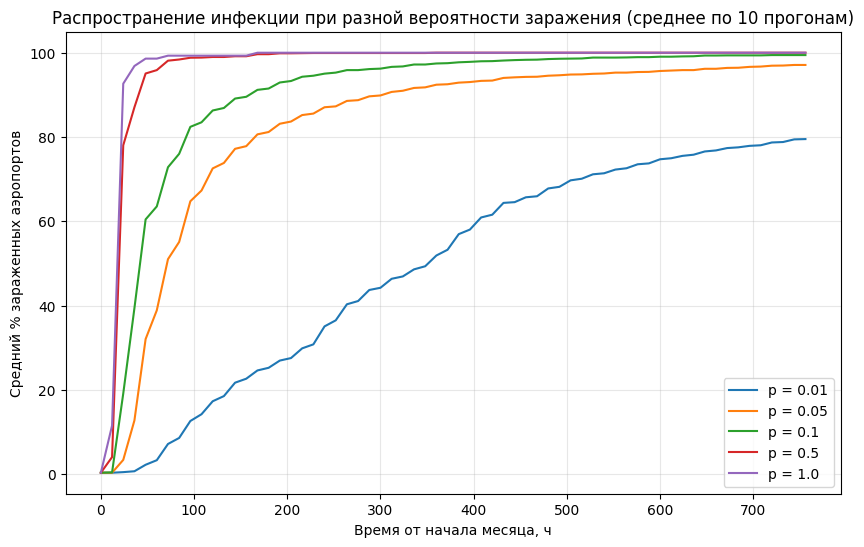

In [130]:
plt.figure(figsize=(10, 6))
for p in probs:
    plt.plot(t_grid, curves[p], label=f'p = {p}')
plt.xlabel('Время от начала месяца, ч')
plt.ylabel('Средний % зараженных аэропортов')
plt.title('Распространение инфекции при разной вероятности заражения (среднее по 10 прогонам)')
plt.grid(alpha=0.3)
plt.legend()
plt.show()

# Сводная таблица

In [131]:
def first_time(curve, threshold):
    return t_grid[np.argmax(curve >= threshold)] if (curve >= threshold).any() else np.nan

summary = pd.DataFrame({
    'p': probs,
    'время до 50%, ч': [first_time(curves[p], 50) for p in probs],
    'время до 90%, ч': [first_time(curves[p], 90) for p in probs],
    'итоговый %': [round(curves[p][-1], 1) for p in probs],
})
display(summary)

,p,"время до 50%, ч","время до 90%, ч",итоговый %
0,0.01,360.0,NaN,79.5
1,0.05,72.0,312.0,97.1
2,0.10,48.0,168.0,99.4
3,0.50,24.0,48.0,100.0
4,1.00,24.0,24.0,100.0


# Часть 3. Построение графа аэропортов
Представляю аэропорты вершинами, а наличие рейсов между двумя аэропортами ребром. Граф делаю ненаправленным, рейсы в обе стороны объединяются в одну пару. Вес ребра равен доле рейсов этой пары от общего числа рейсов.

In [132]:
pairs = pd.DataFrame({
    'a': np.minimum(flights['origin_id'], flights['dest_id']).values,
    'b': np.maximum(flights['origin_id'], flights['dest_id']).values,
})
pairs.head(2)

,a,b
0,83,148
1,141,253


# Подсчёт рейсов между парами
Объединяю направления AB и BA в одну пару. После этого считаю число рейсов для каждой пары аэропортов и делю его на общее количество рейсов, получая вес ребра.

In [133]:
pair_counts = pairs.groupby(['a', 'b']).size().reset_index(name='n_flights')
pair_counts['weight'] = pair_counts['n_flights'] / len(flights)
pair_counts.head(2)

,a,b,n_flights,weight
0,0,16,147,0.000250
1,0,58,151,0.000257


# NetworkX
Добавляю в граф все аэропорты, в тч те, которые могли бы не попасть в список рёбер, и добавляю взвешенные связи. Так я получаю взвешенный ненаправленный граф.

In [134]:
G = nx.Graph()
G.add_nodes_from(range(len(airports)))
G.add_weighted_edges_from(pair_counts[['a', 'b', 'weight']].itertuples(index=False, name=None))

In [135]:
print("Вершин:", G.number_of_nodes())
print("Рёбер:", G.number_of_edges())
print("Сумма весов:", round(sum(d['weight'] for _, _, d in G.edges(data=True)), 6))
print("Рейсов из аэропорта в него же:", (flights['origin_id'] == flights['dest_id']).sum())
print("Граф связный:", nx.is_connected(G))

Вершин: 286
Рёбер: 2319
Сумма весов: 1.0
Рейсов из аэропорта в него же: 0
Граф связный: True


# Наиболее интенсивные маршруты
Вывожу пары с наибольшей долей рейсов и аэропорты с наибольшим числом соседей.

In [136]:
top = pair_counts.sort_values('weight', ascending=False).head(5).copy()
top['пара'] = top['a'].map(lambda i: airports[i]) + ' — ' + top['b'].map(lambda i: airports[i])
display(top[['пара', 'n_flights', 'weight']])

,пара,n_flights,weight
1457,HNL — OGG,2621,0.004464
1715,LAS — LAX,2194,0.003737
1454,HNL — LIH,2190,0.003730
1793,LAX — SFO,2092,0.003563
1741,LAS — PHX,1948,0.003318


In [137]:
deg = pd.Series(dict(G.degree()))
print("Топ-5 по числу соседей:", [(airports[i], d) for i, d in deg.nlargest(5).items()])

Топ-5 по числу соседей: [('ATL', 166), ('ORD', 142), ('DFW', 130), ('DEN', 113), ('DTW', 111)]


# 50 симуляций для оценки времени заражения
Запускаю модель 50 раз при p = 0.5, каждый раз задавая отдельный seed. Для каждого аэропорта сохраняю время. Это позволяет сравнить аэропорты не по одному случайному запуску, а по медиане нескольких запусков.

In [138]:
%%time
N_SIM = 50
P = 0.5

inf_times = np.full((N_SIM, len(airports)), np.inf)

for k in range(N_SIM):
    res = simulate(flights, start='ABE', p=P, seed=k)
    for t, a in res.items():
        inf_times[k, node_id[a]] = t

CPU times: user 18.9 s, sys: 10.8 ms, total: 18.9 s
Wall time: 19 s


# Медианное время заражения
Рассчитываю для каждого аэропорта медиану времени заражения по 50 прогонам. Медиана менее чувствительна к единичным случаям, чем среднее.

In [139]:
median_time = np.median(inf_times, axis=0)
med = pd.Series(median_time, index=airports, name='median_time')

# Проверка результатов симуляций
Проверяю, остались ли аэропорты незаражёнными в каком-либо прогоне и смотрю на аэропорты с самыми ранними и поздними медианными временами.

In [140]:
print("Случаев «аэропорт не заражён в прогоне»:", np.isinf(inf_times).sum(), "из", inf_times.size)
print("Аэропортов с бесконечной медианой:", np.isinf(median_time).sum())
print("Статистика медианного времени, ч:")
print(med[np.isfinite(med)].describe().round(1))
print("Раньше всех заражаются:")
print(med.nsmallest(8).round(1).to_string())
print("Позже всех заражаются:")
print(med.nlargest(8).round(1).to_string())

Случаев «аэропорт не заражён в прогоне»: 0 из 14300
Аэропортов с бесконечной медианой: 0
Статистика медианного времени, ч:
count    286.0
mean      21.4
std       16.5
min        0.0
25%       14.8
50%       16.6
75%       21.6
max      191.4
Name: median_time, dtype: float64
Раньше всех заражаются:
ABE     0.0
DTW     8.1
ORD    10.8
CLT    11.0
MKE    12.1
IND    12.4
CVG    12.5
BWI    12.5
Позже всех заражаются:
PLN    191.4
CDC    158.5
ALO     95.4
ADK     65.3
RHI     64.9
YAK     59.8
WRG     57.4
BLI     47.4


# Распределение времени
Строю гистограмму, чтобы увидеть, какие диапазоны медианного времени встречаются чаще и есть ли аэропорты, заражающиеся значительно позже остальных.

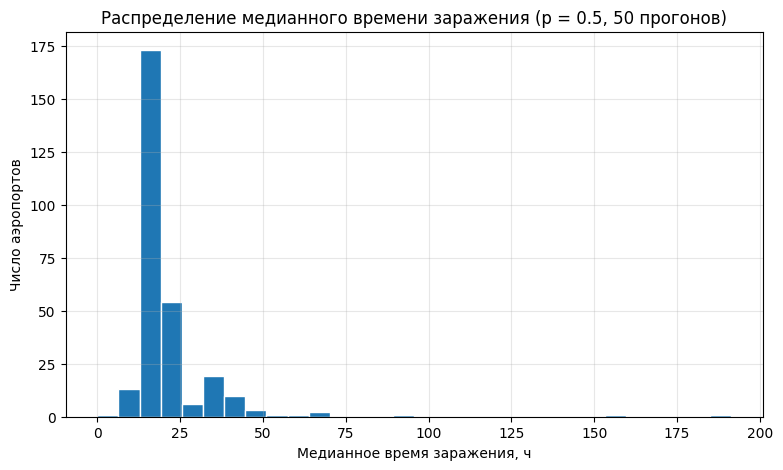

In [141]:
plt.figure(figsize=(9, 5))
plt.hist(med[np.isfinite(med)], bins=30, edgecolor='white')
plt.xlabel('Медианное время заражения, ч')
plt.ylabel('Число аэропортов')
plt.title('Распределение медианного времени заражения (p = 0.5, 50 прогонов)')
plt.grid(alpha=0.3)
plt.show()

# Метрики графа
Рассчитываю три метрики из задания: коэффициент кластеризации, степень вершины и центральность посредничества без весов.

In [142]:
clustering = nx.clustering(G)
degree = dict(nx.degree(G))
betweenness = nx.betweenness_centrality(G)

# Сводная таблица метрик

In [143]:
metrics = pd.DataFrame({
    'median_time': median_time,
    'degree':      [degree[i] for i in range(len(airports))],
    'clustering':  [clustering[i] for i in range(len(airports))],
    'betweenness': [betweenness[i] for i in range(len(airports))],
}, index=airports)

In [144]:
print("Пропуски:", metrics.isna().sum().sum())
print("Аэропортов со степенью 1:", (metrics['degree'] == 1).sum())
print("Аэропортов с кластеризацией 0:", (metrics['clustering'] == 0).sum())
print()
display(metrics.describe().round(3))

Пропуски: 0
Аэропортов со степенью 1: 61
Аэропортов с кластеризацией 0: 65



,median_time,degree,clustering,betweenness
count,286.000,286.000,286.000,286.000
mean,21.422,16.217,0.644,0.005
std,16.486,26.179,0.403,0.021
min,0.000,1.000,0.000,0.000
25%,14.796,2.000,0.230,0.000
50%,16.617,5.000,0.826,0.000
75%,21.571,17.000,1.000,0.000
max,191.400,166.000,1.000,0.232


# Примеры аэропортов и центральные узлы
Отдельно рассматриваю несколько аэропортов с ранним и поздним заражением и вывожу аэропорты с наибольшей центральностью посредничества, чтобы связать численные показатели с конкретными узлами.

In [145]:
early = ['ABE', 'DTW', 'ORD', 'CLT']
late  = ['PLN', 'CDC', 'ALO', 'ADK', 'RHI', 'YAK', 'WRG', 'BLI']
metrics.loc[early + late].round(3)

,median_time,degree,clustering,betweenness
ABE,0.000,7,1.00,0.000
DTW,8.100,111,0.22,0.070
ORD,10.767,142,0.17,0.106
CLT,11.017,69,0.45,0.010
PLN,191.400,1,0.00,0.000
CDC,158.483,2,1.00,0.000
ALO,95.433,1,0.00,0.000
ADK,65.317,1,0.00,0.000
RHI,64.917,1,0.00,0.000
YAK,59.817,2,0.00,0.000


In [146]:
#Топ-8 по центральности (betweenness)
metrics.sort_values('betweenness', ascending=False).head(8).round(3)

,median_time,degree,clustering,betweenness
ATL,12.733,166,0.129,0.232
SLC,14.783,103,0.218,0.119
DFW,13.617,130,0.189,0.116
ORD,10.767,142,0.170,0.106
MSP,13.150,110,0.228,0.097
IAH,13.767,110,0.241,0.072
DTW,8.100,111,0.220,0.070
DEN,14.050,113,0.235,0.062


# Scatter plot и корреляция Спирмена
Строю три диаграммы рассеяния:
1. медианное время заражения против степени;
2. кластеризации;
3. посредничества.

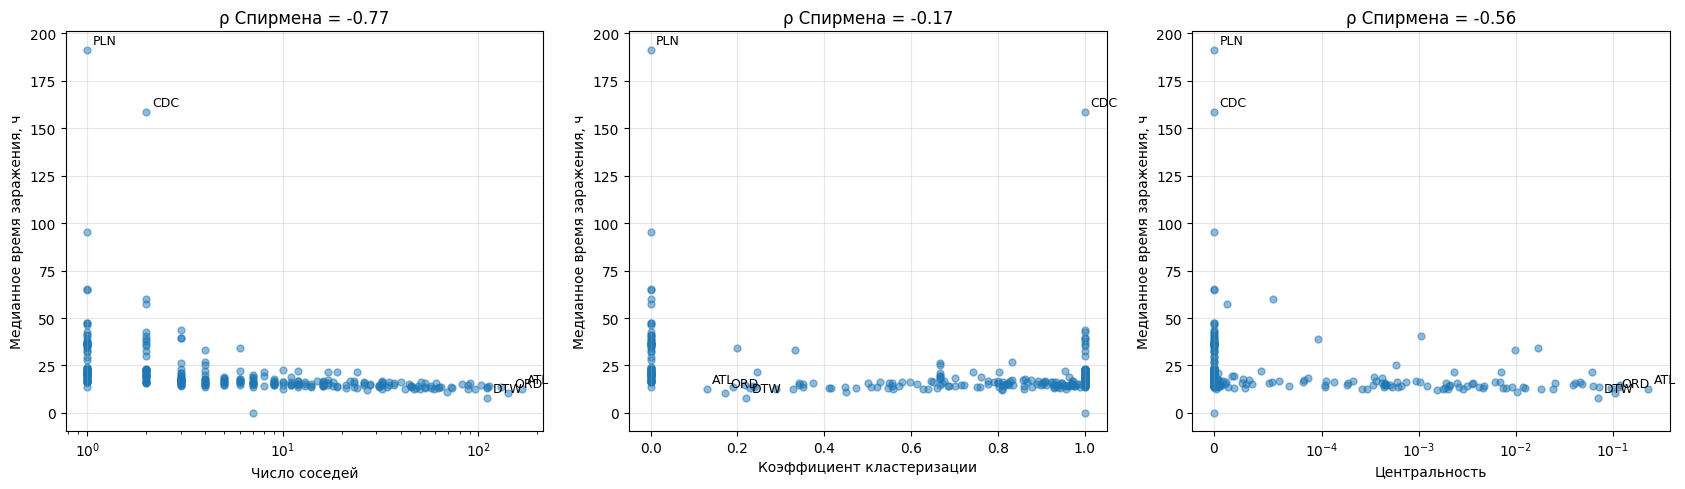

In [147]:
plot_cfg = [
    ('degree','Число соседей', dict(xscale='log')),
    ('clustering', 'Коэффициент кластеризации', dict()),
    ('betweenness', 'Центральность', dict(xscale='symlog', linthresh=1e-4)),
]
label_pts = ['ATL', 'ORD', 'DTW', 'PLN', 'CDC']

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, (col, xlabel, scale) in zip(axes, plot_cfg):
    ax.scatter(metrics[col], metrics['median_time'], alpha=0.5, s=25)
    if 'xscale' in scale:
        if scale['xscale'] == 'symlog':
            ax.set_xscale('symlog', linthresh=scale['linthresh'])
        else:
            ax.set_xscale(scale['xscale'])
    for name in label_pts:
        ax.annotate(name, (metrics.loc[name, col], metrics.loc[name, 'median_time']),
                    fontsize=9, xytext=(4, 4), textcoords='offset points')
    rho, _ = spearmanr(metrics[col], metrics['median_time'])
    ax.set_title(f'ρ Спирмена = {rho:.2f}')
    ax.set_xlabel(xlabel)
    ax.set_ylabel('Медианное время заражения, ч')
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Проверка влияния стартового аэропорта
Рассчитываю корреляции сначала для всей сети, затем исключаю ABE, чтобы проверить, может ли результат определяться только стартовой вершиной.

In [148]:
rows = []
for col in ['degree', 'clustering', 'betweenness']:
    rho_all, p_all = spearmanr(metrics[col], metrics['median_time'])
    m = metrics.drop('ABE')
    rho_no, p_no = spearmanr(m[col], m['median_time'])
    rows.append({'метрика': col,
                 'ρ (все)': round(rho_all, 3), 'p-value (все)': f'{p_all:.1e}',
                 'ρ (без ABE)': round(rho_no, 3), 'p-value (без ABE)': f'{p_no:.1e}'})
display(pd.DataFrame(rows))

,метрика,ρ (все),p-value (все),ρ (без ABE),p-value (без ABE)
0,degree,-0.768,8.4e-57,-0.770,3.3e-57
1,clustering,-0.170,3.9e-03,-0.165,5.2e-03
2,betweenness,-0.558,9.2e-25,-0.567,1.4e-25


# Дополнительный анализ веса связей
Рассчитываю силу вершины (strength) суммы весов рёбер аэропорта, далее сравниваю её корреляцию со временем заражения.

In [149]:
strength = dict(G.degree(weight='weight'))
metrics['strength'] = [strength[i] for i in range(len(airports))]

rho_s, p_s = spearmanr(metrics['strength'], metrics['median_time'])
print(f"strength vs median_time: ρ = {rho_s:.3f}, p = {p_s:.1e}")

strength vs median_time: ρ = -0.813, p = 9.7e-69


In [150]:
rho_db, _ = spearmanr(metrics['degree'], metrics['betweenness'])
print(f"degree vs betweenness:   ρ = {rho_db:.3f}")

degree vs betweenness:   ρ = 0.834


In [151]:
#Аэропорты с одним соседом, медианное время заражения, ч
leaf = metrics[metrics['degree'] == 1]
leaf['median_time'].describe().round(1)

,median_time
count,61.0
mean,32.1
std,25.2
min,13.9
25%,20.0
50%,23.0
75%,36.6
max,191.4


# Итоговые выводы
1. Чем выше вероятность заражения p, тем быстрее и полнее распространяется инфекция, зависимость нелинейная. После прохода по всем рейсам (январь, ~ 750 ч) заражено ~ 80% аэропортов при p = 0.01, 97% при p = 0.05, 99% при p = 0.1 и 100% при p = 0.5 и p = 1. Порог 90% достигается за 312 ч (p = 0.05), 168 ч (p = 0.1), 48 ч (p = 0.5) и 24 ч (p = 1), а при p = 0,01 не достигается.
2. Граф 286 вершин, 2319 рёбер, сумма весов равна 1, граф связный. Вес ребра равен доле рейсов между парой аэропортов во всей сети.
3. Сильнее всего со временем заражения связана степень вершины (ρ Спирмена = -0.77), затем betweenness (-0.56), а кластеризация почти не связана (-0.17). Чем больше у аэропорта соседей и рейсов, тем раньше он заражается. Аэропорт заражается, если хотя бы один из входящих заразных рейсов "сработал". Число соседей напрямую связано с k.
4. Время рейсов вычисляется без приведения местного времени аэропортов к UTC. Поэтому время заражения нужно трактовать как приближённое, метрики clustering, degree и betweenness_centrality рассчитаны без весов, strength отражает суммарный вес связей.